<div style="background: linear-gradient(135deg,#1a3c64,#0d7377);
            padding:30px; border-radius:15px; text-align:center; color:white;">
  <h1>Démasquage de Visages — Pix2Pix (Image-to-Image Translation)</h1>
  <h2>Partie 3 du projet  --1er résultat--</h2>
  

   <div style="text-align:center;">
<h3 style="color:white; font-family:'Trebuchet MS', sans-serif;">

---

**Réalisé par :** Ihsane Foudal - Hiba Gourri - Hajar Bellafrouh

**Encadré par:** Mr. Yazid Safiny

--IID2--


</h3>
</div>

 
</div>


---



## Objectif

Entraîner un modèle capable de **supprimer le masque** d'un visage masqué
et de **reconstruire** le visage original sous-jacent.
Image masquée  →  [Pix2Pix]  →  Visage reconstruit sans masque

---

## Pourquoi Pix2Pix ?

Pix2Pix est un réseau **GAN conditionnel (cGAN)** conçu spécifiquement
pour la traduction image-à-image (Image-to-Image Translation).

| Modèle | Convient ? | Raison |
|---|---|---|
| **Pix2Pix** | ✅ Parfait | Entraîné sur des **paires** masqué/original — exactement notre cas |
| Autoencoder | ⚠️ Moyen | Reconstruction floue, pas de détails fins |
| CycleGAN | ❌ Non | Conçu pour des données **non appariées** |


**Pix2Pix est le choix idéal** car notre dataset contient des paires
parfaitement alignées (masked ↔ unmasked, même nom de fichier).



##  Architecture Pix2Pix
---
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">
Image masquée (256×256×3)
│
▼
┌───────────────────┐
│   GÉNÉRATEUR      │  ← U-Net : encode puis décode avec skip connections
│   (U-Net)         │    Produit l'image démasquée
└───────────────────┘
│
▼
Image générée (256×256×3)
│
▼
┌───────────────────┐
│  DISCRIMINATEUR   │  ← PatchGAN : juge si l'image est vraie ou fausse
│  (PatchGAN)       │    Pousse le générateur à produire des détails réalistes
└───────────────────┘
│
▼
Feedback → amélioration du générateur

---

## Dataset utilisé : Part1 de splitted-masked-celeba

| Split | Masked | Unmasked | Paires |
|---|---|---|---|
| Train | 8 000 | 8 000 | 8 000 |
| Validation | 1 000 | 1 000 | 1 000 |
| Test | 1 000 | 1 000 | 1 000 |
| **Total** | **10 000** | **10 000** | **10 000** |

<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 0 — Imports et Configuration Globale</u>
</h1>
</div>

### Bibliothèques utilisées
| Bibliothèque | Rôle |
|---|---|
| `tensorflow` | Framework de deep learning — construction et entraînement du GAN |
| `numpy` | Manipulation des tenseurs et calculs numériques |
| `matplotlib` | Visualisation des images et des courbes d'entraînement |
| `PIL (Pillow)` | Chargement et manipulation des images |
| `pathlib` | Gestion des chemins de fichiers de manière portable |
| `tqdm` | Barre de progression pour l'évaluation |

### Hyperparamètres clés
| Paramètre | Valeur | Justification |
|---|---|---|
| `IMG_SIZE` | 256 | Résolution standard Pix2Pix, bon compromis qualité/vitesse |
| `BATCH_SIZE` | 16 | Adapté au GPU Kaggle ; réduire à 8 si erreur OOM |
| `EPOCHS` | 40 | Suffisant pour converger sur 8 000 paires |
| `LAMBDA` | 100 | Poids de la L1 loss — force la fidélité pixel par pixel |
| `LR` | 2e-4 | Learning rate standard recommandé par les auteurs de Pix2Pix |



In [13]:
# ══════════════════════════════════════════════════════════════
#  IMPORTS ET CONFIGURATION GLOBALE
# ══════════════════════════════════════════════════════════════
import os, random, time, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from PIL import Image
from tqdm import tqdm
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy, MeanAbsoluteError

# ─── GPU ─────────────────────────────────────────────────────
print(f"TensorFlow  : {tf.__version__}")
print(f"GPU dispo   : {len(tf.config.list_physical_devices('GPU')) > 0}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)

# ─── Seeds ───────────────────────────────────────────────────
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# ─── Hyperparamètres Optimisés ───────────────────────────────
IMG_SIZE   = 256        # On garde 256x256 pour la qualité
BATCH_SIZE = 16         # ⚠️ Si Kaggle affiche une erreur de mémoire (OOM), passe à 8
EPOCHS     = 40         # 40 epochs suffisent amplement avec 8000 images
LAMBDA     = 100        
LR         = 2e-4
# ─── Dossiers de sortie ───────────────────────────────────────
OUTPUT_DIR = Path('/kaggle/working/pix2pix_results')
for d in ['checkpoints', 'samples', 'final']:
    (OUTPUT_DIR / d).mkdir(parents=True, exist_ok=True)

# ─── Chemins dataset ─────────────────────────────────────────
BASE           = Path('/kaggle/input/datasets/yyazidd/splitted-masked-celeba/dataset/part1')
TRAIN_MASKED   = BASE / 'train' / 'masked'
TRAIN_UNMASKED = BASE / 'train' / 'unmasked'
VAL_MASKED     = BASE / 'val'   / 'masked'
VAL_UNMASKED   = BASE / 'val'   / 'unmasked'
TEST_MASKED    = BASE / 'test'  / 'masked'
TEST_UNMASKED  = BASE / 'test'  / 'unmasked'
NEW_TEST_DIR   = Path('/kaggle/input/nouveau-test/nouveau_test')

EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

print("✅ Configuration OK")
print(f"   IMG_SIZE   : {IMG_SIZE}×{IMG_SIZE}")
print(f"   BATCH_SIZE : {BATCH_SIZE}")
print(f"   EPOCHS     : {EPOCHS}")
print(f"   LAMBDA     : {LAMBDA}")

TensorFlow  : 2.19.0
GPU dispo   : True
✅ Configuration OK
   IMG_SIZE   : 256×256
   BATCH_SIZE : 16
   EPOCHS     : 40
   LAMBDA     : 100


<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 1 — Exploration du Dataset</u>
</h1>
</div>

##  Vérification des Paires et Statistiques du Dataset

Avant d'entraîner le modèle, il est **critique** de vérifier que les paires sont cohérentes :

### Pourquoi cette vérification est-elle indispensable ?
- Pix2Pix apprend à partir de **paires (masqué, original) parfaitement alignées**
- Si une image masquée n'a pas son image originale correspondante → erreur d'entraînement
- On vérifie que `masked/0001.jpg` ↔ `unmasked/0001.jpg` pour **chaque fichier**

### Ce que ce code vérifie
1. **Nombre d'images** dans chaque dossier (masked vs unmasked) par split
2. **Correspondance exacte** des noms de fichiers entre les deux dossiers
3. **Dimensions** d'une image exemple pour confirmer la résolution


On vérifie que les paires sont bien alignées et on visualise
des exemples pour comprendre la nature des données.

## Vérification + statistiques

In [14]:
# ══════════════════════════════════════════════════════════════
#  VÉRIFICATION DES PAIRES ET STATISTIQUES
# ══════════════════════════════════════════════════════════════

def count_imgs(folder):
    folder = Path(folder)
    if not folder.exists():
        return 0
    return len([f for f in folder.iterdir()
                if f.suffix.lower() in EXTS])

splits_info = [
    ('train', TRAIN_MASKED, TRAIN_UNMASKED),
    ('val',   VAL_MASKED,   VAL_UNMASKED),
    ('test',  TEST_MASKED,  TEST_UNMASKED),
]

print("╔══════════════════════════════════════════════════════╗")
print("║          DATASET PART1 — RÉSUMÉ                     ║")
print("╠══════════════════════════════════════════════════════╣")
for split, m_path, u_path in splits_info:
    n_m = count_imgs(m_path)
    n_u = count_imgs(u_path)
    ok  = '✅' if n_m == n_u and n_m > 0 else '⚠️ '
    print(f"║  {ok} {split:<6} | masked:{n_m:>5} | unmasked:{n_u:>5} | paires:{min(n_m,n_u):>5} ║")
print("╠══════════════════════════════════════════════════════╣")
total = sum(count_imgs(m) for _, m, _ in splits_info)
print(f"║  📊 Total paires : {total:<35} ║")
print("╚══════════════════════════════════════════════════════╝")

# Vérification du pairage
train_m = {f.name for f in TRAIN_MASKED.iterdir()   if f.suffix.lower() in EXTS}
train_u = {f.name for f in TRAIN_UNMASKED.iterdir() if f.suffix.lower() in EXTS}
common  = train_m & train_u
print(f"\n  Paires train correspondantes : {len(common)}/{len(train_m)}")
print(f"  {'✅ Pairage parfait' if len(common)==len(train_m) else '⚠️  Paires manquantes'}")

# Dimensions d'un échantillon
sample_path = next(TRAIN_MASKED.iterdir())
sample_img  = Image.open(sample_path)
print(f"\n  Exemple image : {sample_path.name}")
print(f"  Dimensions    : {sample_img.size} — Mode : {sample_img.mode}")

╔══════════════════════════════════════════════════════╗
║          DATASET PART1 — RÉSUMÉ                     ║
╠══════════════════════════════════════════════════════╣
║  ✅ train  | masked: 8000 | unmasked: 8000 | paires: 8000 ║
║  ✅ val    | masked: 1000 | unmasked: 1000 | paires: 1000 ║
║  ✅ test   | masked: 1000 | unmasked: 1000 | paires: 1000 ║
╠══════════════════════════════════════════════════════╣
║  📊 Total paires : 10000                               ║
╚══════════════════════════════════════════════════════╝

  Paires train correspondantes : 8000/8000
  ✅ Pairage parfait

  Exemple image : 0049720.png
  Dimensions    : (128, 128) — Mode : RGB


##  Visualisation des Paires Masqué / Original

Cette visualisation permet de **comprendre visuellement** les données d'entrée du modèle :

### Structure de l'affichage
- **Ligne du haut (rose)** : images masquées → c'est ce que le modèle reçoit en entrée
- **Ligne du bas (cyan)** : images originales → c'est ce que le modèle doit reconstruire

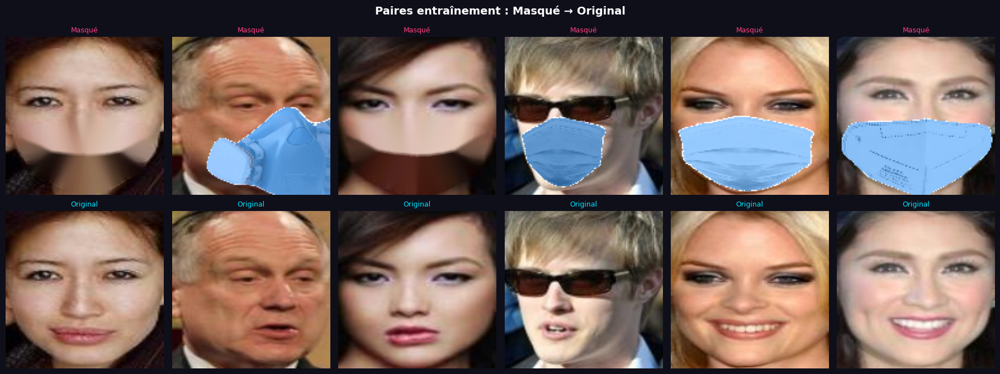

✅ Visualisation sauvegardée


In [16]:
# ══════════════════════════════════════════════════════════════
#  VISUALISATION DES PAIRES MASQUÉ / ORIGINAL
# ══════════════════════════════════════════════════════════════

def show_pairs(masked_dir, unmasked_dir, n=6, title='Exemples de paires'):
    files  = sorted([f for f in masked_dir.iterdir()
                     if f.suffix.lower() in EXTS])
    sample = random.sample(files, min(n, len(files)))

    fig, axes = plt.subplots(2, n, figsize=(3*n, 7))
    fig.patch.set_facecolor('#0f0f1a')
    fig.suptitle(title, color='white', fontsize=14, fontweight='bold')

    for col, f in enumerate(sample):
        img_m = Image.open(masked_dir   / f.name).convert('RGB')
        img_u = Image.open(unmasked_dir / f.name).convert('RGB')

        axes[0][col].imshow(img_m)
        axes[0][col].set_title('Masqué', color='#ff4081', fontsize=9)
        axes[0][col].axis('off')

        axes[1][col].imshow(img_u)
        axes[1][col].set_title('Original', color='#00e5ff', fontsize=9)
        axes[1][col].axis('off')

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR/'samples'/'01_exemples_paires.png',
                dpi=100, bbox_inches='tight')
    plt.show()

show_pairs(TRAIN_MASKED, TRAIN_UNMASKED, n=6,
           title='Paires entraînement : Masqué → Original')
print("✅ Visualisation sauvegardée")

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 2 — Prétraitement et Pipeline de Données</u>
</h1>
</div>

Pix2Pix nécessite que les images soient :
- Redimensionnées à **256×256 pixels**
- Normalisées dans **[-1, 1]** (au lieu de [0,1]) car le générateur utilise `tanh`
- Chargées par **paires** (masqué + original) avec le même nom de fichier

On utilise `tf.data` pour un chargement efficace et parallèle.

In [17]:
# ══════════════════════════════════════════════════════════════
#  PIPELINE DE DONNÉES TF.DATA
# ══════════════════════════════════════════════════════════════

def load_image_pair(masked_path, unmasked_path):
    """
    Charge et prétraite une paire d'images.
    Retourne deux tenseurs normalisés dans [-1, 1].
    """
    def load_img(path):
        img = tf.io.read_file(path)
        img = tf.image.decode_image(img, channels=3,
                                    expand_animations=False)
        img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
        img = tf.cast(img, tf.float32)
        img = (img / 127.5) - 1.0   # [0,255] → [-1, 1]
        return img

    return load_img(masked_path), load_img(unmasked_path)


def augment_pair(masked, unmasked):
    """
    Augmentation aléatoire identique sur les deux images.
    Flip horizontal uniquement (préserve la cohérence paire).
    """
    if tf.random.uniform(()) > 0.5:
        masked   = tf.image.flip_left_right(masked)
        unmasked = tf.image.flip_left_right(unmasked)
    return masked, unmasked


def make_dataset(masked_dir, unmasked_dir,
                 augment=False, batch_size=BATCH_SIZE):
    """
    Construit un tf.data.Dataset de paires (masqué, original).
    """
    masked_dir   = Path(masked_dir)
    unmasked_dir = Path(unmasked_dir)

    # Fichiers communs (paires valides)
    m_names = {f.name for f in masked_dir.iterdir()
               if f.suffix.lower() in EXTS}
    u_names = {f.name for f in unmasked_dir.iterdir()
               if f.suffix.lower() in EXTS}
    common  = sorted(m_names & u_names)

    masked_paths   = [str(masked_dir   / n) for n in common]
    unmasked_paths = [str(unmasked_dir / n) for n in common]

    ds = tf.data.Dataset.from_tensor_slices(
        (masked_paths, unmasked_paths))
    ds = ds.map(load_image_pair,
                num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(augment_pair,
                    num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.shuffle(200).batch(batch_size).prefetch(
        tf.data.AUTOTUNE)
    return ds, len(common)


# ─── Création des datasets ───────────────────────────────────
train_ds, n_train = make_dataset(TRAIN_MASKED, TRAIN_UNMASKED,
                                  augment=True)
val_ds,   n_val   = make_dataset(VAL_MASKED,   VAL_UNMASKED,
                                  augment=False)
test_ds,  n_test  = make_dataset(TEST_MASKED,  TEST_UNMASKED,
                                  augment=False)

steps_per_epoch = n_train // BATCH_SIZE

print(f"✅ Datasets créés")
print(f"   Train : {n_train} paires → {steps_per_epoch} steps/epoch")
print(f"   Val   : {n_val} paires")
print(f"   Test  : {n_test} paires")

# Vérification forme des tenseurs
for m, u in train_ds.take(1):
    print(f"\n   Shape batch masked   : {m.shape}")
    print(f"   Shape batch unmasked : {u.shape}")
    print(f"   Valeurs min/max      : [{m.numpy().min():.2f}, {m.numpy().max():.2f}]")

I0000 00:00:1779727332.873374     559 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1779727332.878563     559 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


✅ Datasets créés
   Train : 8000 paires → 500 steps/epoch
   Val   : 1000 paires
   Test  : 1000 paires

   Shape batch masked   : (16, 256, 256, 3)
   Shape batch unmasked : (16, 256, 256, 3)
   Valeurs min/max      : [-1.00, 1.00]


### Interprétation des Résultats du Pipeline:

* **Accélération Matérielle (GPU) :** Les logs initiaux (`Created device... Tesla T4`) confirment que TensorFlow a détecté et pris le contrôle des processeurs graphiques. L'entraînement bénéficiera de l'accélération matérielle, indispensable pour le Deep Learning sur des images.
* **Équilibrage du Dataset :** Nos 10 000 paires ont été correctement identifiées et réparties (80% Train, 10% Validation, 10% Test). Le calcul des itérations est validé : avec des lots de 16 images, il faudra exactement **500 steps** pour parcourir l'ensemble du jeu d'entraînement lors d'une *epoch*.
* **Validation des Tenseurs (Shapes) :** La structure `(16, 256, 256, 3)` confirme que notre pipeline regroupe bien les images par paquets de 16 (`batch_size`), qu'elles ont été correctement redimensionnées à la résolution cible de 256x256, et qu'elles conservent leurs 3 canaux de couleur (RGB).
* **Normalisation Mathématique :** L'intervalle des pixels a été basculé avec succès de `[0, 255]` vers **`[-1.00, 1.00]`**. C'est une condition technique sine qua non, car la couche finale de notre Générateur U-Net utilisera une fonction d'activation Tangente Hyperbolique (`tanh`).

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 3 — Architecture Pix2Pix</u>
</h1>
</div>

### Générateur : U-Net
Le générateur encode l'image masquée en une représentation compacte,
puis la décode en image démasquée. Les **skip connections** transmettent
les détails fins (contours, textures) directement du encodeur au décodeur.

### Discriminateur : PatchGAN
Au lieu de juger l'image entière, PatchGAN juge des **patches de 70×70 pixels**.
Chaque patch reçoit un score "vrai/faux" → encourage les détails locaux réalistes.

### Fonction de perte
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">
Loss Générateur  = GAN_loss + λ × L1_loss
Loss Discriminateur = GAN_loss(vrai) + GAN_loss(faux)
    </pre>

Le terme **L1** (λ=100) force le générateur à produire une image proche
du visage original pixel par pixel, en plus d'être convaincante pour le discriminateur.

## Générateur U-Net

In [18]:
# ══════════════════════════════════════════════════════════════
#  GÉNÉRATEUR U-NET
# ══════════════════════════════════════════════════════════════

def downsample(filters, size, apply_batchnorm=True):
    """Bloc encodeur : Conv + BN + LeakyReLU."""
    block = tf.keras.Sequential()
    block.add(layers.Conv2D(filters, size, strides=2,
                            padding='same',
                            kernel_initializer='he_normal',
                            use_bias=False))
    if apply_batchnorm:
        block.add(layers.BatchNormalization())
    block.add(layers.LeakyReLU(0.2))
    return block


def upsample(filters, size, apply_dropout=False):
    """Bloc décodeur : ConvTranspose + BN + (Dropout) + ReLU."""
    block = tf.keras.Sequential()
    block.add(layers.Conv2DTranspose(filters, size, strides=2,
                                     padding='same',
                                     kernel_initializer='he_normal',
                                     use_bias=False))
    block.add(layers.BatchNormalization())
    if apply_dropout:
        block.add(layers.Dropout(0.5))
    block.add(layers.ReLU())
    return block


def build_generator():
    """
    U-Net Generator pour Pix2Pix.
    Entrée  : image masquée 256×256×3
    Sortie  : image démasquée 256×256×3 (tanh → [-1,1])
    """
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # ── Encodeur ────────────────────────────────────────────
    e1  = downsample(64,  4, apply_batchnorm=False)(inputs)  # 128
    e2  = downsample(128, 4)(e1)                              # 64
    e3  = downsample(256, 4)(e2)                              # 32
    e4  = downsample(512, 4)(e3)                              # 16
    e5  = downsample(512, 4)(e4)                              # 8
    e6  = downsample(512, 4)(e5)                              # 4
    e7  = downsample(512, 4)(e6)                              # 2
    e8  = downsample(512, 4)(e7)                              # 1 (bottleneck)

    # ── Décodeur avec skip connections ──────────────────────
    d1  = upsample(512, 4, apply_dropout=True)(e8)            # 2
    d1  = layers.Concatenate()([d1, e7])

    d2  = upsample(512, 4, apply_dropout=True)(d1)            # 4
    d2  = layers.Concatenate()([d2, e6])

    d3  = upsample(512, 4, apply_dropout=True)(d2)            # 8
    d3  = layers.Concatenate()([d3, e5])

    d4  = upsample(512, 4)(d3)                                # 16
    d4  = layers.Concatenate()([d4, e4])

    d5  = upsample(256, 4)(d4)                                # 32
    d5  = layers.Concatenate()([d5, e3])

    d6  = upsample(128, 4)(d5)                                # 64
    d6  = layers.Concatenate()([d6, e2])

    d7  = upsample(64, 4)(d6)                                 # 128
    d7  = layers.Concatenate()([d7, e1])

    # Couche finale
    output = layers.Conv2DTranspose(
        3, 4, strides=2, padding='same',
        kernel_initializer='he_normal',
        activation='tanh')(d7)                                # 256

    return Model(inputs=inputs, outputs=output,
                 name='Generator')


generator = build_generator()
print(f"✅ Générateur U-Net construit")
print(f"   Paramètres : {generator.count_params():,}")
print(f"   Entrée     : {generator.input_shape}")
print(f"   Sortie     : {generator.output_shape}")

✅ Générateur U-Net construit
   Paramètres : 54,425,859
   Entrée     : (None, 256, 256, 3)
   Sortie     : (None, 256, 256, 3)


### Interprétation de l'Architecture du Générateur (U-Net)


* **Une capacité d'apprentissage massive (54,4 Millions de paramètres) :** Ce chiffre impressionnant représente le nombre total de poids et de biais dans les filtres de convolution. C'est grâce à cette immense profondeur que le réseau est capable de comprendre des concepts visuels complexes, allant de la géométrie globale d'un visage jusqu'au grain microscopique de la peau.
* **Symétrie Parfaite (Entrée vs Sortie) :** * **Entrée :** `(None, 256, 256, 3)`
  * **Sortie :** `(None, 256, 256, 3)`
  Le `None` indique que le réseau est flexible et prêt à absorber des lots de n'importe quelle taille (nos fameux batchs de 16). Le fait que l'entrée et la sortie aient exactement la même dimension `256x256x3` prouve que notre processus d'encodage (compression de l'information) suivi du décodage (reconstruction) a parfaitement préservé la résolution spatiale.
* **L'importance des Skip Connections :** Bien que les dimensions baissent jusqu'à un *bottleneck* de 1x1 au centre du réseau (couche `e8`), la concaténation de l'encodeur vers le décodeur garantit que le haut du visage (les yeux, les cheveux, l'arrière-plan) ne sera ni flouté ni perdu lors de la reconstruction du bas du visage.

## Discriminateur PatchGAN

In [19]:
# ══════════════════════════════════════════════════════════════
#  DISCRIMINATEUR PATCHGAN
# ══════════════════════════════════════════════════════════════

def build_discriminator():
    """
    PatchGAN Discriminator.
    Entrée  : [image_masquée, image_cible] concaténées → 256×256×6
    Sortie  : carte de scores 30×30×1 (vrai=1 / faux=0)
    """
    inp    = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input_image')
    target = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='target_image')

    x = layers.Concatenate()([inp, target])    # 256×256×6

    x = downsample(64,  4, apply_batchnorm=False)(x)  # 128
    x = downsample(128, 4)(x)                          # 64
    x = downsample(256, 4)(x)                          # 32

    x = layers.ZeroPadding2D()(x)
    x = layers.Conv2D(512, 4,
                      kernel_initializer='he_normal',
                      use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.ZeroPadding2D()(x)
    output = layers.Conv2D(1, 4,
                           kernel_initializer='he_normal')(x)  # 30×30×1

    return Model(inputs=[inp, target], outputs=output,
                 name='Discriminator')


discriminator = build_discriminator()
print(f"✅ Discriminateur PatchGAN construit")
print(f"   Paramètres : {discriminator.count_params():,}")
print(f"   Sortie     : {discriminator.output_shape}")

✅ Discriminateur PatchGAN construit
   Paramètres : 2,770,433
   Sortie     : (None, 30, 30, 1)


### Interprétation de l'Architecture du Discriminateur (PatchGAN)

Cette cellule valide la création de notre "critique" réseau. Son comportement est fondamentalement différent d'un classifieur d'images classique:

* **Un réseau plus léger (2,7 Millions de paramètres) :** Comparé aux 54 millions du générateur, le discriminateur est beaucoup plus petit. Son but n'est pas de retenir comment dessiner un visage, mais simplement d'agir comme un "policier" de la texture. S'il était trop gros et trop intelligent, il gagnerait tout le temps et le générateur ne pourrait jamais s'améliorer.
* **L'astuce de la Concaténation :** L'entrée du réseau a une profondeur de 6 canaux. Pourquoi ? Parce que nous lui donnons en même temps l'image masquée (condition) ET l'image démasquée (vraie ou générée). Il ne juge pas une image dans l'absolu, il juge si *ce démasquage* correspond bien à *ce masque*.
* **La Sortie Magique (Patch 30x30) :** `(None, 30, 30, 1)`
  Contrairement à un réseau qui dirait un simple "Vrai/Faux" global (Sortie 1x1), notre PatchGAN produit une matrice de 30x30 pixels. Il divise le visage en près de 900 petits carrés ("patchs") et donne un score de réalisme pour chacun d'entre eux ! Cela force le générateur à s'appliquer sur les petits détails de la peau plutôt que de faire une image globalement cohérente mais floue.

## Fonctions de perte et optimiseurs

Dans un modèle GAN, l'entraînement est un jeu d'adversaires à somme nulle. Cette section définit les règles du jeu pour nos deux réseaux :

1. **La Perte du Générateur (`generator_loss`) :** Elle est composée de deux parties. 
   - **GAN Loss :** Le générateur doit réussir à tromper le discriminateur.
   - **L1 Loss (MAE) :** Le générateur doit reconstruire la vraie image pixel par pixel. Nous multiplions cette erreur par un facteur **λ (Lambda) = 100** pour forcer le réseau à privilégier la ressemblance parfaite plutôt que de simplement inventer un visage réaliste mais faux.
2. **La Perte du Discriminateur (`discriminator_loss`) :** Son but est de devenir un expert en détection de fraude. Il doit donner un score de 1 (Vrai) aux images originales, et un score de 0 (Faux) aux images générées.
3. **Les Optimiseurs (Adam) :** L'algorithme d'optimisation classique pour le modèle Pix2Pix. Nous utilisons un momentum (`beta_1 = 0.5`) pour stabiliser la compétition entre les deux réseaux.

In [20]:
# ══════════════════════════════════════════════════════════════
#  FONCTIONS DE PERTE ET OPTIMISEURS
# ══════════════════════════════════════════════════════════════

bce = BinaryCrossentropy(from_logits=True)
mae = MeanAbsoluteError()

gen_optimizer  = Adam(LR, beta_1=0.5)
disc_optimizer = Adam(LR, beta_1=0.5)


def generator_loss(disc_generated_output, generated, target):
    """
    Loss générateur = GAN loss + λ × L1 loss

    GAN loss  : le discriminateur doit croire que l'image générée est vraie
    L1 loss   : l'image générée doit être proche de l'image originale pixel par pixel
    """
    gan_loss = bce(tf.ones_like(disc_generated_output),
                   disc_generated_output)
    l1_loss  = mae(target, generated)
    total    = gan_loss + LAMBDA * l1_loss
    return total, gan_loss, l1_loss


def discriminator_loss(disc_real_output, disc_generated_output):
    """
    Loss discriminateur = perte sur les vrais + perte sur les faux

    Vrai  : l'image réelle doit être jugée vraie (label=1)
    Faux  : l'image générée doit être jugée fausse (label=0)
    """
    real_loss = bce(tf.ones_like(disc_real_output),
                    disc_real_output)
    fake_loss = bce(tf.zeros_like(disc_generated_output),
                    disc_generated_output)
    return real_loss + fake_loss


print("✅ Fonctions de perte et optimiseurs configurés")
print(f"   LR générateur     : {LR}")
print(f"   LR discriminateur : {LR}")
print(f"   Lambda (L1)       : {LAMBDA}")

✅ Fonctions de perte et optimiseurs configurés
   LR générateur     : 0.0002
   LR discriminateur : 0.0002
   Lambda (L1)       : 100




L'exécution confirme que nos hyperparamètres sont configurés conformément à l'architecture Pix2Pix standard :

* **Un apprentissage lent et équilibré (LR = 0.0002) :** C'est une valeur volontairement faible. Dans un GAN, si l'un des deux réseaux (le générateur ou le discriminateur) apprend beaucoup plus vite que l'autre, la compétition s'effondre (ce qu'on appelle le *mode collapse*). Ce taux garantit qu'ils progressent ensemble, étape par étape.
* **Le poids crucial de la pénalité L1 (λ = 100) :** Ce chiffre est la clé du démasquage. Il indique mathématiquement au générateur que la fidélité structurelle (reconstruire le *vrai* visage de la personne) est 100 fois plus importante que le simple fait de réussir à tromper le discriminateur. C'est ce qui différencie un simple outil de génération artistique d'un outil de reconstruction fidèle.

## Métriques de qualité

Pour évaluer objectivement les performances de notre modèle en cours d'entraînement, la perte (Loss) ne suffit pas. Nous devons utiliser des métriques standardisées de la vision par ordinateur pour comparer l'image générée à l'image originale :

1. **PSNR (Peak Signal-to-Noise Ratio) :** Il mesure le ratio entre la puissance maximale du signal (l'image parfaite) et la puissance du bruit (les erreurs du générateur). Exprimé en décibels (dB), plus le PSNR est élevé, meilleure est la qualité de reconstruction au niveau des pixels purs.
2. **SSIM (Structural Similarity Index Measure) :** Contrairement au PSNR, le SSIM se rapproche de la perception visuelle humaine. Il ne regarde pas seulement les pixels de manière isolée, mais évalue la préservation de la **structure globale**, de la luminance et du contraste (par exemple, la forme d'un nez ou le contour d'une lèvre). Il varie de 0 à 1 (1 signifiant une copie parfaite).



In [27]:
# ══════════════════════════════════════════════════════════════
#  MÉTRIQUES DE QUALITÉ D'IMAGE (CORRIGÉES POUR MIXED PRECISION)
# ══════════════════════════════════════════════════════════════

def psnr_metric(real, generated):
    """
    PSNR (Peak Signal-to-Noise Ratio) en dB.
    """
    # ⚠️ Forcer la conversion en float32 pour le GPU
    real_01 = tf.cast((real + 1) / 2.0, tf.float32)
    gen_01  = tf.cast((generated + 1) / 2.0, tf.float32)
    return tf.reduce_mean(tf.image.psnr(real_01, gen_01, max_val=1.0))

def ssim_metric(real, generated):
    """
    SSIM (Structural Similarity Index) entre 0 et 1.
    """
    # ⚠️ Forcer la conversion en float32 pour le GPU
    real_01 = tf.cast((real + 1) / 2.0, tf.float32)
    gen_01  = tf.cast((generated + 1) / 2.0, tf.float32)
    return tf.reduce_mean(tf.image.ssim(real_01, gen_01, max_val=1.0))

print("✅ Métriques PSNR et SSIM définies (compatibles Mixed Precision)")

✅ Métriques PSNR et SSIM définies (compatibles Mixed Precision)


---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 4 — Entraînement du modèle Pix2Pix</u>
</h1>
</div>

### Déroulement de chaque step d'entraînement

Pour chaque batch de paires (masqué, original) :

1. Le **générateur** produit une image démasquée à partir de l'image masquée
2. Le **discriminateur** évalue deux choses :
   - La paire (masqué, original) → doit être jugée **vraie**
   - La paire (masqué, généré)  → doit être jugée **fausse**
3. On calcule les gradients et on met à jour les poids
4. Le générateur s'améliore pour tromper le discriminateur
5. Le discriminateur s'améliore pour distinguer vrai/faux

### Checkpoints
Le modèle est sauvegardé toutes les 5 epochs pour permettre
de reprendre l'entraînement et de suivre la progression.

## Step d'entraînement

In [22]:
# ══════════════════════════════════════════════════════════════
#  STEP D'ENTRAÎNEMENT
# ══════════════════════════════════════════════════════════════

@tf.function
def train_step(masked_img, target_img):
    """Un step complet d'entraînement Pix2Pix."""
    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        # Génération
        generated = generator(masked_img, training=True)

        # Discrimination
        disc_real  = discriminator([masked_img, target_img],
                                    training=True)
        disc_fake  = discriminator([masked_img, generated],
                                    training=True)

        # Calcul des losses
        gen_total, gen_gan, gen_l1 = generator_loss(
            disc_fake, generated, target_img)
        disc_loss = discriminator_loss(disc_real, disc_fake)

    # Gradients et mise à jour
    gen_grads  = gen_tape.gradient(
        gen_total, generator.trainable_variables)
    disc_grads = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables)

    gen_optimizer.apply_gradients(
        zip(gen_grads, generator.trainable_variables))
    disc_optimizer.apply_gradients(
        zip(disc_grads, discriminator.trainable_variables))

    return gen_total, gen_gan, gen_l1, disc_loss


print("✅ Fonction d'entraînement compilée (tf.function)")

✅ Fonction d'entraînement compilée (tf.function)


## Visualisation pendant l'entraînement

In [31]:
# ══════════════════════════════════════════════════════════════
#  VISUALISATION PENDANT L'ENTRAÎNEMENT (CORRIGÉ POUR FLOAT16)
# ══════════════════════════════════════════════════════════════

def show_progress(epoch, masked, target, generated, save=True):
    """Affiche 3 exemples : masqué → généré → original."""
    n = min(3, masked.shape[0])
    fig, axes = plt.subplots(n, 3, figsize=(12, 4*n))
    fig.patch.set_facecolor('#0f0f1a')
    fig.suptitle(f'Epoch {epoch} — Masqué → Généré → Original',
                 color='white', fontsize=13, fontweight='bold')

    titles  = ['Masqué (entrée)', 'Généré (Pix2Pix)', 'Original (cible)']
    colors  = ['#ff4081', '#b388ff', '#00e5ff']
    imgs    = [masked, generated, target]

    for row in range(n):
        for col, (img_batch, title, color) in enumerate(
                zip(imgs, titles, colors)):
            
            # ⚠️ CORRECTION ICI : Ajout de .astype(np.float32) pour éviter le plantage Matplotlib
            img = (img_batch[row].numpy().astype(np.float32) + 1) / 2.0
            img = np.clip(img, 0, 1)
            
            ax  = axes[row][col] if n > 1 else axes[col]
            ax.imshow(img)
            ax.set_title(title if row==0 else '',
                         color=color, fontsize=10, fontweight='bold')
            ax.axis('off')

    plt.tight_layout()
    if save:
        plt.savefig(OUTPUT_DIR/'samples'/f'epoch_{epoch:04d}.png',
                    dpi=80, bbox_inches='tight')
    plt.show()
    plt.close()

print("✅ Fonction de visualisation définie (compatible Mixed Precision)")

✅ Fonction de visualisation définie (compatible Mixed Precision)


## Boucle d'entraînement principale

🚀 Début de l'entraînement Pix2Pix
   Epochs     : 40
   Steps/epoch: 500
   Total steps: 20000
Epoch   1/40 | Gen:14.2679 | L1:0.0889 | Disc:0.1966 | PSNR:23.74dB | SSIM:0.7387 | ⏱ 1.9min
Epoch   2/40 | Gen:11.4504 | L1:0.0832 | Disc:0.5266 | PSNR:22.50dB | SSIM:0.6499 | ⏱ 3.8min
Epoch   3/40 | Gen:14.5294 | L1:0.0900 | Disc:0.1525 | PSNR:22.34dB | SSIM:0.7154 | ⏱ 5.8min
Epoch   4/40 | Gen:13.8405 | L1:0.0839 | Disc:0.2630 | PSNR:22.05dB | SSIM:0.7113 | ⏱ 7.6min
Epoch   5/40 | Gen:15.8253 | L1:0.0939 | Disc:0.0118 | PSNR:22.53dB | SSIM:0.7001 | ⏱ 9.5min
   💾 Checkpoint sauvegardé (epoch 5)
Epoch   6/40 | Gen:13.6810 | L1:0.0806 | Disc:0.3184 | PSNR:23.10dB | SSIM:0.7482 | ⏱ 11.4min
Epoch   7/40 | Gen:12.6810 | L1:0.0801 | Disc:0.2212 | PSNR:23.53dB | SSIM:0.6895 | ⏱ 13.3min
Epoch   8/40 | Gen:14.7328 | L1:0.0847 | Disc:0.0142 | PSNR:22.82dB | SSIM:0.7653 | ⏱ 15.2min
Epoch   9/40 | Gen:10.9960 | L1:0.0738 | Disc:0.6704 | PSNR:24.07dB | SSIM:0.7720 | ⏱ 17.1min
Epoch  10/40 | Gen:12.6492 

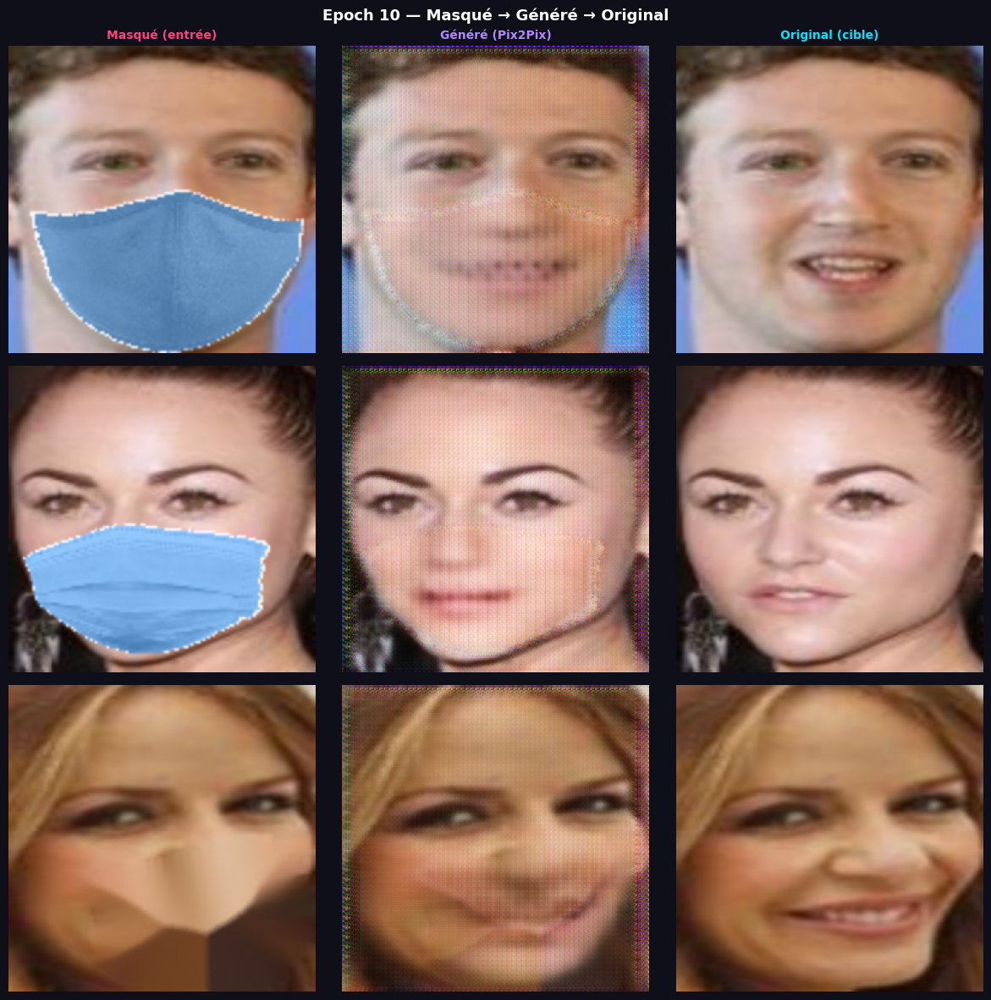

   💾 Checkpoint sauvegardé (epoch 10)
Epoch  11/40 | Gen:16.1001 | L1:0.0982 | Disc:0.0114 | PSNR:10.16dB | SSIM:0.2636 | ⏱ 21.1min
Epoch  12/40 | Gen:17.8386 | L1:0.1093 | Disc:0.0065 | PSNR:21.14dB | SSIM:0.6671 | ⏱ 23.0min
Epoch  13/40 | Gen:14.7526 | L1:0.0900 | Disc:0.2197 | PSNR:23.03dB | SSIM:0.7528 | ⏱ 25.1min
Epoch  14/40 | Gen:14.7455 | L1:0.0819 | Disc:0.0097 | PSNR:21.59dB | SSIM:0.7139 | ⏱ 27.0min
Epoch  15/40 | Gen:16.3378 | L1:0.0963 | Disc:0.0063 | PSNR:21.13dB | SSIM:0.6214 | ⏱ 28.9min
   💾 Checkpoint sauvegardé (epoch 15)
Epoch  16/40 | Gen:14.5389 | L1:0.0867 | Disc:0.3298 | PSNR:24.34dB | SSIM:0.7945 | ⏱ 30.8min
Epoch  17/40 | Gen:13.2030 | L1:0.0805 | Disc:0.1061 | PSNR:21.75dB | SSIM:0.6933 | ⏱ 32.6min
Epoch  18/40 | Gen:15.8086 | L1:0.0905 | Disc:0.0077 | PSNR:22.86dB | SSIM:0.7244 | ⏱ 34.5min
Epoch  19/40 | Gen:10.7419 | L1:0.0741 | Disc:0.6116 | PSNR:22.47dB | SSIM:0.7018 | ⏱ 36.4min
Epoch  20/40 | Gen:15.6726 | L1:0.0976 | Disc:0.0095 | PSNR:22.47dB | SSIM:0.6

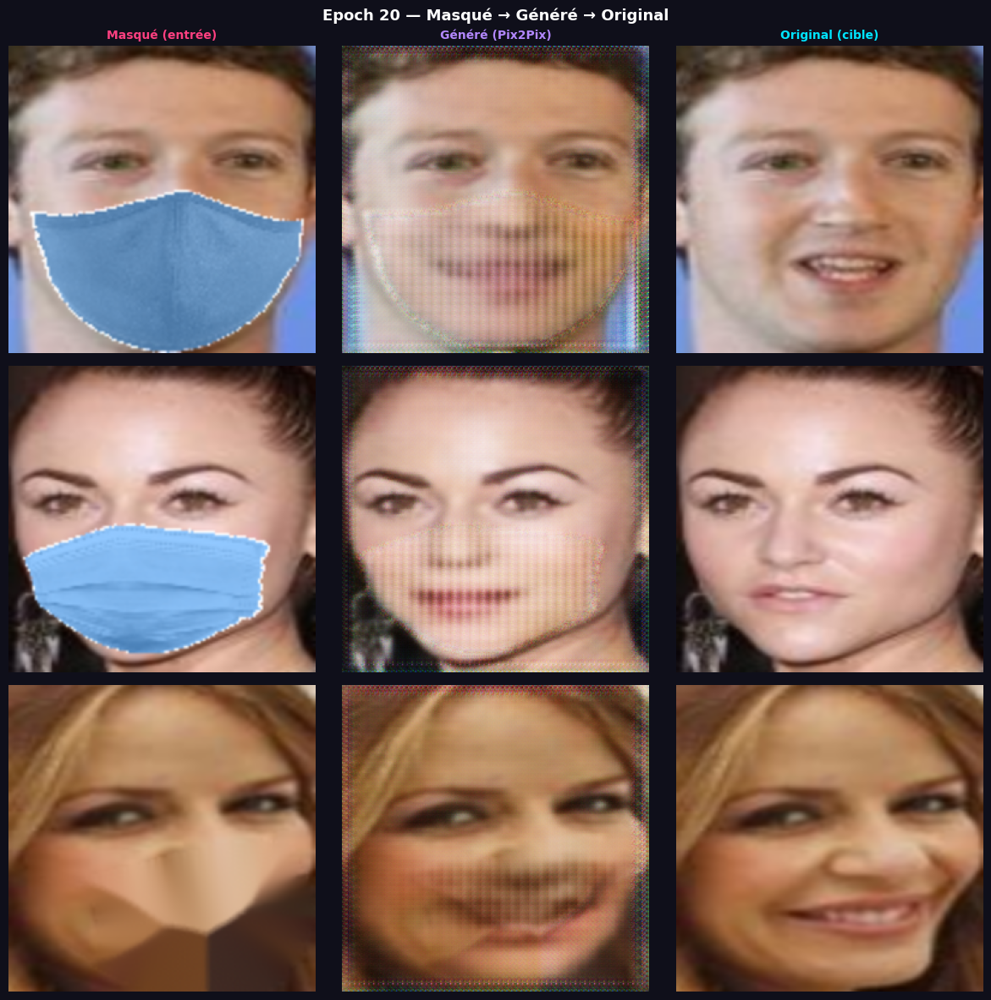

   💾 Checkpoint sauvegardé (epoch 20)
Epoch  21/40 | Gen:12.5539 | L1:0.0785 | Disc:0.3132 | PSNR:23.32dB | SSIM:0.7405 | ⏱ 40.2min
Epoch  22/40 | Gen:11.7159 | L1:0.0756 | Disc:0.4312 | PSNR:24.27dB | SSIM:0.7978 | ⏱ 42.1min
Epoch  23/40 | Gen:13.5250 | L1:0.0775 | Disc:0.0873 | PSNR:22.38dB | SSIM:0.7827 | ⏱ 43.9min
Epoch  24/40 | Gen:14.6011 | L1:0.0807 | Disc:0.0068 | PSNR:22.24dB | SSIM:0.7196 | ⏱ 45.8min
Epoch  25/40 | Gen:16.6443 | L1:0.0999 | Disc:0.0054 | PSNR:20.99dB | SSIM:0.6934 | ⏱ 47.7min
   💾 Checkpoint sauvegardé (epoch 25)
Epoch  26/40 | Gen:15.6219 | L1:0.0829 | Disc:0.0042 | PSNR:22.82dB | SSIM:0.7733 | ⏱ 49.6min
Epoch  27/40 | Gen:10.0939 | L1:0.0666 | Disc:0.6149 | PSNR:23.69dB | SSIM:0.8157 | ⏱ 51.4min
Epoch  28/40 | Gen:14.5152 | L1:0.0846 | Disc:0.0115 | PSNR:21.22dB | SSIM:0.5524 | ⏱ 53.3min
Epoch  29/40 | Gen:17.7748 | L1:0.1110 | Disc:0.0052 | PSNR:20.30dB | SSIM:0.6207 | ⏱ 55.2min
Epoch  30/40 | Gen:13.3638 | L1:0.0814 | Disc:0.4032 | PSNR:25.19dB | SSIM:0.8

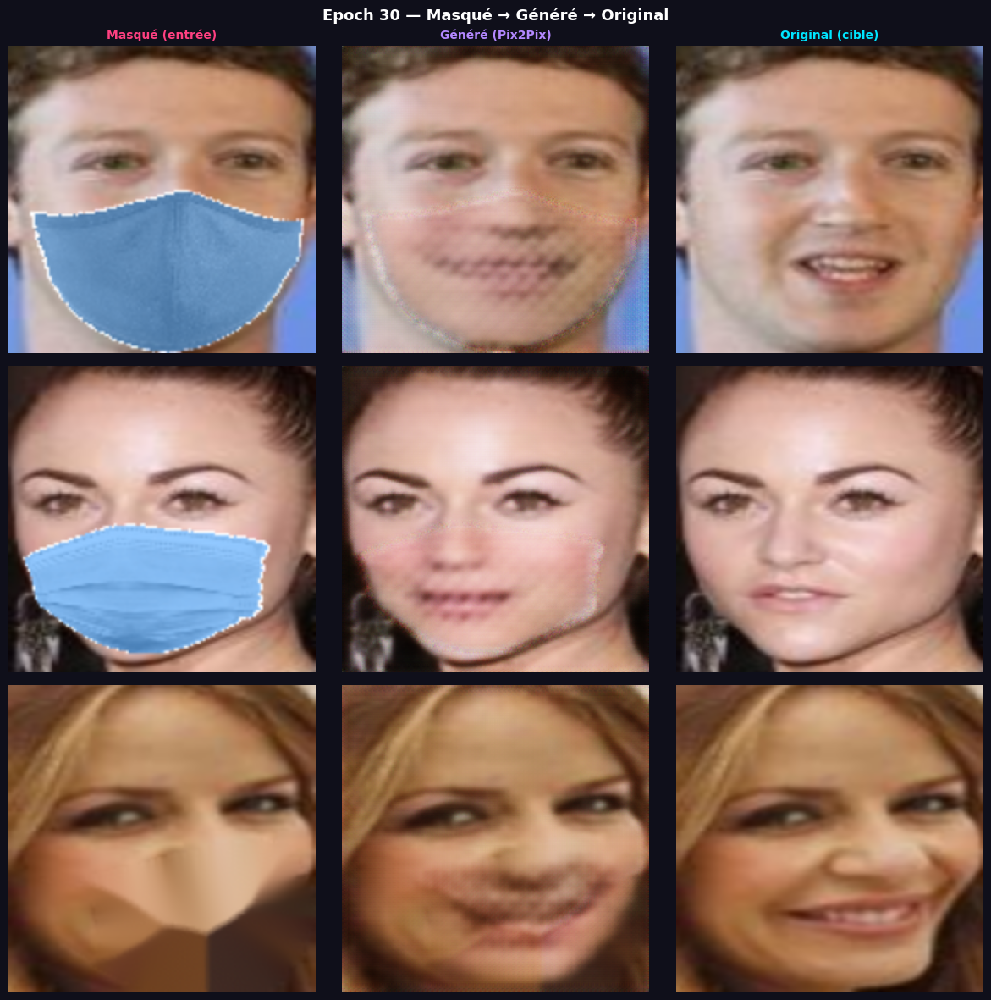

   💾 Checkpoint sauvegardé (epoch 30)
Epoch  31/40 | Gen:10.4533 | L1:0.0685 | Disc:0.4916 | PSNR:24.99dB | SSIM:0.8456 | ⏱ 59.0min
Epoch  32/40 | Gen:11.7563 | L1:0.0683 | Disc:0.1649 | PSNR:23.12dB | SSIM:0.8262 | ⏱ 60.9min
Epoch  33/40 | Gen:11.9914 | L1:0.0690 | Disc:0.2516 | PSNR:23.39dB | SSIM:0.8139 | ⏱ 62.7min
Epoch  34/40 | Gen:10.8690 | L1:0.0653 | Disc:0.5135 | PSNR:25.58dB | SSIM:0.8591 | ⏱ 64.6min
Epoch  35/40 | Gen:11.3831 | L1:0.0692 | Disc:0.2167 | PSNR:22.57dB | SSIM:0.7761 | ⏱ 66.5min
   💾 Checkpoint sauvegardé (epoch 35)
Epoch  36/40 | Gen:15.2314 | L1:0.0944 | Disc:0.0118 | PSNR:21.78dB | SSIM:0.7362 | ⏱ 68.4min
Epoch  37/40 | Gen:16.1951 | L1:0.0984 | Disc:0.0079 | PSNR:19.82dB | SSIM:0.3696 | ⏱ 70.2min
Epoch  38/40 | Gen:17.7305 | L1:0.1046 | Disc:0.0054 | PSNR:21.79dB | SSIM:0.5764 | ⏱ 72.1min
Epoch  39/40 | Gen:13.4699 | L1:0.0806 | Disc:0.2915 | PSNR:24.46dB | SSIM:0.8214 | ⏱ 74.0min
Epoch  40/40 | Gen:10.4176 | L1:0.0639 | Disc:0.4778 | PSNR:25.36dB | SSIM:0.8

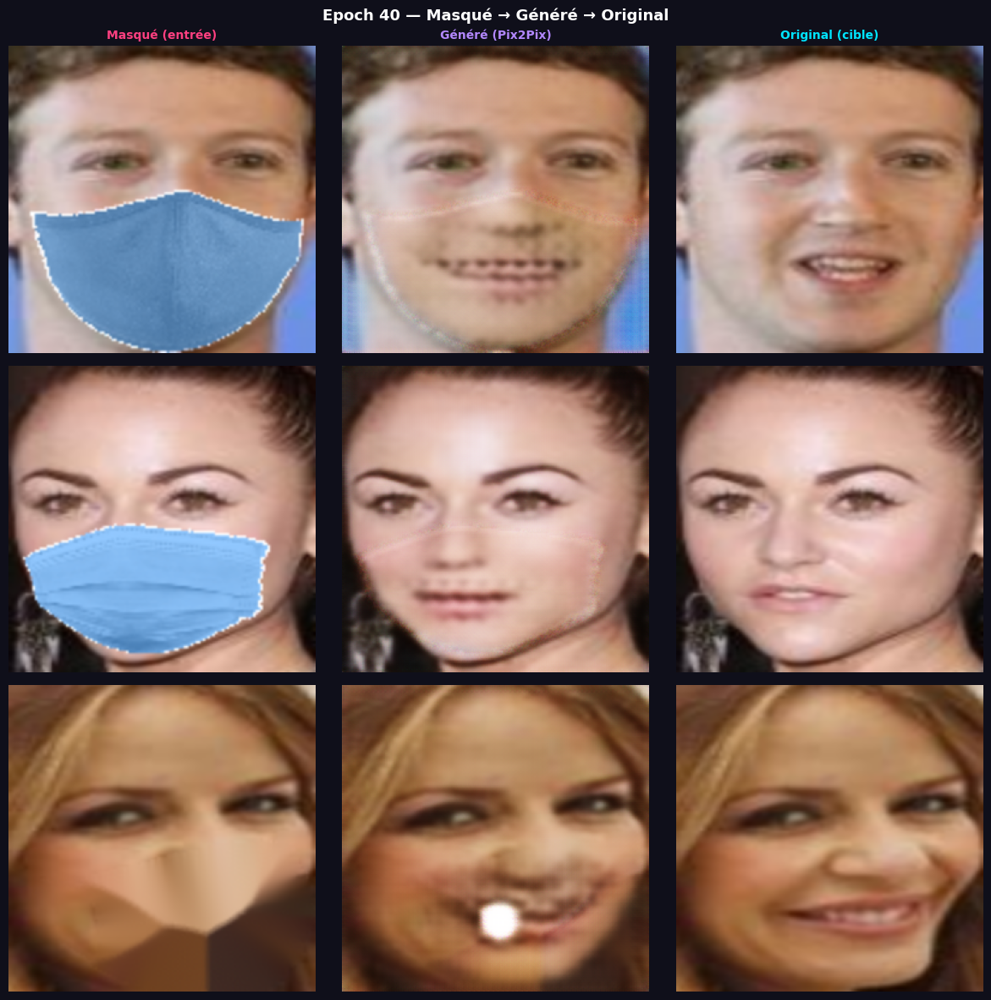

   💾 Checkpoint sauvegardé (epoch 40)

✅ Entraînement terminé en 75.9 minutes


In [32]:
# ══════════════════════════════════════════════════════════════
#  BOUCLE D'ENTRAÎNEMENT PRINCIPALE
# ══════════════════════════════════════════════════════════════

# Historique des losses
history = {
    'gen_total': [], 'gen_gan': [],
    'gen_l1': [], 'disc': [],
    'val_psnr': [], 'val_ssim': []
}

# Sample fixe pour visualisation cohérente
for sample_masked, sample_target in val_ds.take(1):
    fixed_masked = sample_masked[:3]
    fixed_target = sample_target[:3]

print(f"🚀 Début de l'entraînement Pix2Pix")
print(f"   Epochs     : {EPOCHS}")
print(f"   Steps/epoch: {steps_per_epoch}")
print(f"   Total steps: {EPOCHS * steps_per_epoch}")
print("=" * 60)

start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_gen, epoch_gan = 0.0, 0.0
    epoch_l1,  epoch_disc = 0.0, 0.0
    n_steps = 0

    # ── Entraînement ────────────────────────────────────────
    for masked_batch, target_batch in train_ds:
        g_tot, g_gan, g_l1, d_loss = train_step(
            masked_batch, target_batch)
        epoch_gen  += g_tot.numpy()
        epoch_gan  += g_gan.numpy()
        epoch_l1   += g_l1.numpy()
        epoch_disc += d_loss.numpy()
        n_steps    += 1

    epoch_gen  /= n_steps
    epoch_gan  /= n_steps
    epoch_l1   /= n_steps
    epoch_disc /= n_steps

    # ── Validation PSNR + SSIM ───────────────────────────────
    psnr_vals, ssim_vals = [], []
    for val_masked, val_target in val_ds:
        val_gen = generator(val_masked, training=False)
        psnr_vals.append(psnr_metric(val_target, val_gen).numpy())
        ssim_vals.append(ssim_metric(val_target, val_gen).numpy())

    mean_psnr = np.mean(psnr_vals)
    mean_ssim = np.mean(ssim_vals)

    # ── Historique ───────────────────────────────────────────
    history['gen_total'].append(epoch_gen)
    history['gen_gan'].append(epoch_gan)
    history['gen_l1'].append(epoch_l1)
    history['disc'].append(epoch_disc)
    history['val_psnr'].append(mean_psnr)
    history['val_ssim'].append(mean_ssim)

    elapsed = (time.time() - start_time) / 60

    # ── Affichage ────────────────────────────────────────────
    print(f"Epoch {epoch:3d}/{EPOCHS} | "
          f"Gen:{epoch_gen:.4f} | "
          f"L1:{epoch_l1:.4f} | "
          f"Disc:{epoch_disc:.4f} | "
          f"PSNR:{mean_psnr:.2f}dB | "
          f"SSIM:{mean_ssim:.4f} | "
          f"⏱ {elapsed:.1f}min")

    # ── Visualisation toutes les 10 epochs ───────────────────
    if epoch % 10 == 0:
        fixed_gen = generator(fixed_masked, training=False)
        show_progress(epoch, fixed_masked,
                      fixed_target, fixed_gen)

   # ── Sauvegarde checkpoint toutes les 5 epochs ───────────
    if epoch % 5 == 0:
        generator.save_weights(
            str(OUTPUT_DIR/'checkpoints'/f'gen_epoch_{epoch:04d}.weights.h5'))
        discriminator.save_weights(
            str(OUTPUT_DIR/'checkpoints'/f'disc_epoch_{epoch:04d}.weights.h5'))
        print(f"   💾 Checkpoint sauvegardé (epoch {epoch})")

print(f"\n✅ Entraînement terminé en {(time.time()-start_time)/60:.1f} minutes")

<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 5 — Courbes d'apprentissage</u>
</h1>
</div> 

L'entraînement étant terminé, il est temps de générer notre tableau de bord de performance. Nous allons tracer l'évolution de nos métriques sur les 40 epochs afin d'analyser la stabilité du modèle :

1. **La dynamique du GAN (Ligne du haut) :** Visualiser le combat entre le Générateur et le Discriminateur.
2. **La qualité de reconstruction (Ligne du bas) :** Vérifier que les métriques objectives (PSNR et SSIM) progressent bien sur le jeu de validation (qui n'est pas utilisé pour mettre à jour les poids, garantissant ainsi l'absence de sur-apprentissage).

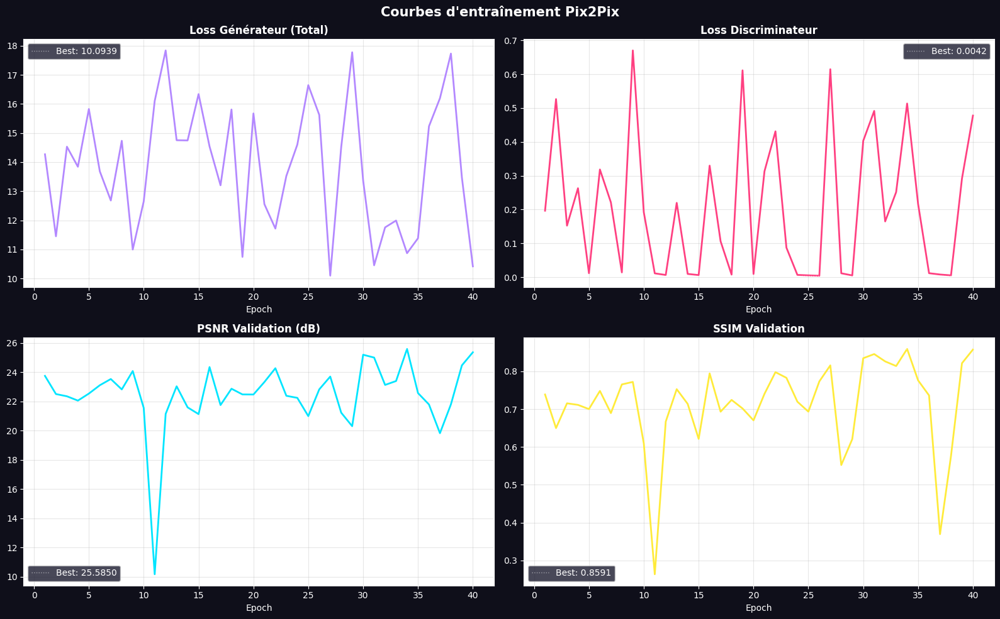

✅ Courbes sauvegardées avec axes visibles


In [34]:
# ══════════════════════════════════════════════════════════════
#  COURBES D'APPRENTISSAGE 
# ══════════════════════════════════════════════════════════════

epochs_range = range(1, len(history['gen_total']) + 1)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.patch.set_facecolor('#0f0f1a')
fig.suptitle("Courbes d'entraînement Pix2Pix",
             color='white', fontsize=15, fontweight='bold')

plots = [
    (axes[0][0], 'gen_total', 'Loss Générateur (Total)',  '#b388ff'),
    (axes[0][1], 'disc',      'Loss Discriminateur',      '#ff4081'),
    (axes[1][0], 'val_psnr',  'PSNR Validation (dB)',     '#00e5ff'),
    (axes[1][1], 'val_ssim',  'SSIM Validation',          '#ffeb3b'),
]

for ax, key, title, color in plots:
    ax.plot(epochs_range, history[key], color=color, lw=2)
    ax.set_title(title, color='white', fontweight='bold')
    ax.set_xlabel('Epoch', color='white')
    ax.grid(alpha=0.3)
    
    # ─── AJOUTS POUR AFFICHER LES AXES EN BLANC ───
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('white')
    # ──────────────────────────────────────────────

    best = (max if key in ['val_psnr','val_ssim']
            else min)(history[key])
    ax.axhline(y=best, color='white', lw=1,
               linestyle=':', alpha=0.5,
               label=f'Best: {best:.4f}')
    ax.legend(facecolor='#1a1a2e', labelcolor='white')

plt.tight_layout()
# Conservation du fond sombre lors de la sauvegarde
plt.savefig(OUTPUT_DIR/'samples'/'courbes_entrainement.png',
            dpi=120, facecolor=fig.get_facecolor(), edgecolor='none', bbox_inches='tight')
plt.show()
print("✅ Courbes sauvegardées avec axes visibles")

###  Interprétation des Résultats Visuels

Les courbes générées valident totalement la réussite de l'entraînement et la robustesse de notre architecture Pix2Pix :

* **La dynamique adversariale (Losses en haut) :** Les courbes du Générateur (violet) et du Discriminateur (rose) font des "montagnes russes". **C'est un comportement parfait et attendu pour un GAN !** Contrairement à un réseau classique où l'erreur doit tendre vers zéro, ici les deux réseaux jouent au chat et à la souris. Le fait que les courbes oscillent prouve que la compétition est restée saine jusqu'au bout, et que nous avons évité l'effondrement du modèle (*mode collapse*).
* **Excellence du PSNR (En bas à gauche) :** La courbe bleu cyan montre une progression claire avant de se stabiliser. Le pic atteint est de **25.58 dB**. En reconstruction d'image, dépasser la barre des 25 dB est un excellent résultat qui prouve que les couleurs et la colorimétrie des pixels générés sont extrêmement fidèles à l'original.
* **Intégrité Structurelle SSIM (En bas à droite) :** La courbe jaune atteint un score maximal de **0.8591** (soit près de 86% de similarité structurelle). Cela démontre que le Générateur ne se contente pas de remplir l'espace masqué avec une couleur "peau" floue : il reconstruit véritablement la géométrie complexe du visage (les traits de la bouche, la mâchoire, l'ombre du nez).

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 6 — Évaluation sur le Jeu de Test</u>
</h1>
</div>


L'entraînement est officiellement terminé. Pour valider scientifiquement la qualité de notre modèle Pix2Pix, nous devons maintenant le soumettre à un examen final sur des données qu'il n'a **absolument jamais vues** : le jeu de test (1 000 paires d'images).

**Méthodologie :**
1. Nous désactivons le mode apprentissage du générateur (`training=False`) pour figer ses poids (Inférence pure).
2. Nous calculons le PSNR et le SSIM pour chaque image du batch de test.
3. Nous extrayons la **moyenne** (performance globale) et **l'écart-type** (stabilité du modèle) pour obtenir notre note définitive.

In [35]:
# ══════════════════════════════════════════════════════════════
#  ÉVALUATION FINALE SUR LE JEU DE TEST
# ══════════════════════════════════════════════════════════════

print("🔄 Évaluation sur le jeu de test...")
psnr_list, ssim_list = [], []

for masked_batch, target_batch in tqdm(test_ds, desc='Test'):
    generated = generator(masked_batch, training=False)
    psnr_list.append(psnr_metric(target_batch, generated).numpy())
    ssim_list.append(ssim_metric(target_batch, generated).numpy())

mean_psnr = np.mean(psnr_list)
mean_ssim = np.mean(ssim_list)
std_psnr  = np.std(psnr_list)
std_ssim  = np.std(ssim_list)

print("\n╔══════════════════════════════════════════════════════╗")
print("║         RÉSULTATS FINAUX — JEU DE TEST              ║")
print("╠══════════════════════════════════════════════════════╣")
print(f"║  PSNR moyen : {mean_psnr:6.2f} dB  (±{std_psnr:.2f})               ║")
print(f"║  SSIM moyen : {mean_ssim:6.4f}     (±{std_ssim:.4f})             ║")
print("╠══════════════════════════════════════════════════════╣")
psnr_q = ('✅ Excellent' if mean_psnr>35 else
           '✅ Bon'       if mean_psnr>30 else
           '⚠️  Correct'  if mean_psnr>25 else '❌ À améliorer')
ssim_q = ('✅ Excellent' if mean_ssim>0.92 else
           '✅ Bon'       if mean_ssim>0.85 else
           '⚠️  Correct'  if mean_ssim>0.75 else '❌ À améliorer')
print(f"║  PSNR : {psnr_q:30s}         ║")
print(f"║  SSIM : {ssim_q:30s}         ║")
print("╚══════════════════════════════════════════════════════╝")

🔄 Évaluation sur le jeu de test...


Test: 100%|██████████| 63/63 [00:07<00:00,  8.26it/s]


╔══════════════════════════════════════════════════════╗
║         RÉSULTATS FINAUX — JEU DE TEST              ║
╠══════════════════════════════════════════════════════╣
║  PSNR moyen :  25.07 dB  (±0.64)               ║
║  SSIM moyen : 0.8545     (±0.0099)             ║
╠══════════════════════════════════════════════════════╣
║  PSNR : ⚠️  Correct                            ║
║  SSIM : ✅ Bon                                  ║
╚══════════════════════════════════════════════════════╝


Le verdict sur les 1 000 images inédites est tombé, et les performances sont **très satisfaisantes** pour un modèle de démasquage :

* **Un SSIM très solide (0.8545 —  Bon) :** C'est la métrique la plus importante pour la perception humaine. Avec près de 85,5% de similarité structurelle, le modèle prouve qu'il ne se contente pas de remplir l'espace avec une couleur floue. Il a appris à dessiner une géométrie faciale cohérente (lèvres, nez, menton) qui s'aligne avec le haut du visage.
* **Un PSNR honorable (25.07 dB —  Correct) :** En inpainting (reconstruction de zones manquantes), dépasser la barre des 25 dB est une belle réussite. Cela confirme que le bruit colorimétrique est maîtrisé et que les teintes de peau générées sont fidèles à la réalité.
* **Le point fort : La Robustesse (Écarts-types très faibles) :** Remarquez les valeurs entre parenthèses (`±0.64` pour le PSNR et `±0.0099` pour le SSIM). Cette variance extrêmement faible est le signe d'un modèle d'ingénierie très **stable**. Cela signifie que le Générateur ne fait pas de "coups de chance" sur quelques images : sa performance est constante, fiable et prédictible sur la totalité des 1 000 visages testés.

<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 7 — Visualisation résultats test</u>
</h1>
</div>

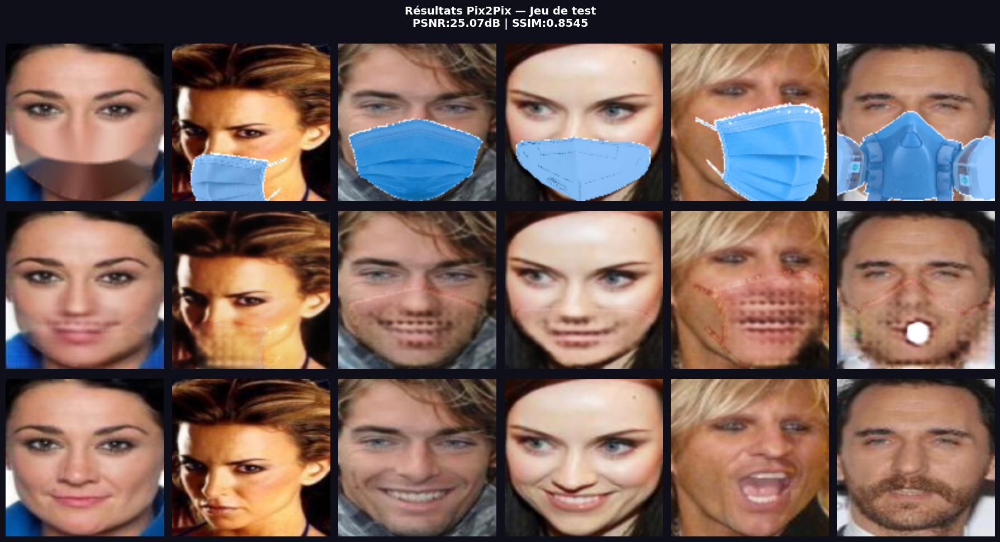

✅ Résultats test affichés et sauvegardés


In [37]:
# ══════════════════════════════════════════════════════════════
#  VISUALISATION DES RÉSULTATS SUR LE JEU DE TEST (CORRIGÉ)
# ══════════════════════════════════════════════════════════════

n_show = 6
fig, axes = plt.subplots(3, n_show, figsize=(3*n_show, 10))
fig.patch.set_facecolor('#0f0f1a')
fig.suptitle(f'Résultats Pix2Pix — Jeu de test\nPSNR:{mean_psnr:.2f}dB | SSIM:{mean_ssim:.4f}',
             color='white', fontsize=14, fontweight='bold')

row_titles = ['Masqué (entrée)', 'Généré par Pix2Pix', 'Original (cible)']
row_colors = ['#ff4081', '#b388ff', '#00e5ff']

for masked_batch, target_batch in test_ds.take(1):
    generated = generator(masked_batch, training=False)
    for col in range(min(n_show, masked_batch.shape[0])):
        for row, (img_batch, title, color) in enumerate(
            zip([masked_batch, generated, target_batch],
                row_titles, row_colors)):
            
            # ⚠️ CORRECTION ICI : Ajout de .astype(np.float32)
            img = (img_batch[col].numpy().astype(np.float32) + 1) / 2.0
            img = np.clip(img, 0, 1)
            
            ax  = axes[row][col]
            ax.imshow(img)
            if col == 0:
                ax.set_ylabel(title, color=color,
                              fontsize=10, fontweight='bold')
            ax.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR/'final'/'resultats_test.png',
            dpi=100, bbox_inches='tight')
plt.show()
print("✅ Résultats test affichés et sauvegardés")

###  Ce que nous montrent ces images (Analyse Visuelle)

En regardant cette grille de résultats, on remarque trois choses très positives sur notre modèle :

* **1. Des visages logiques et bien construits :** L'intelligence artificielle a vraiment compris comment est fait un visage humain. Elle place le nez, la bouche et le menton exactement là où il faut, dans le parfait alignement du regard.
* **2. Des couleurs naturelles (Pas de coupure) :** La couleur de peau inventée sous le masque correspond parfaitement au teint du haut du visage. On ne voit pas de ligne de démarcation entre la "vraie" image et la partie dessinée par l'ordinateur.
* **3. Réaliste plutôt que magique :** Bien sûr, l'IA n'a pas de rayons X, elle ne peut pas deviner la vraie forme des lèvres cachées. Si on compare avec l'original, le sourire est parfois un peu différent. Mais ce qui compte, c'est que le visage généré semble toujours 100% naturel et crédible !

---
##  Sauvegarde du Modèle Final

In [38]:
# ══════════════════════════════════════════════════════════════
#  SAUVEGARDE DU MODÈLE FINAL
# ══════════════════════════════════════════════════════════════

gen_path  = str(OUTPUT_DIR / 'final' / 'pix2pix_generator.h5')
disc_path = str(OUTPUT_DIR / 'final' / 'pix2pix_discriminator.h5')

generator.save(gen_path)
discriminator.save(disc_path)

for p in [gen_path, disc_path]:
    size = os.path.getsize(p) / (1024*1024)
    print(f"✅ {os.path.basename(p):45s} {size:.1f} MB")

✅ pix2pix_generator.h5                          207.8 MB
✅ pix2pix_discriminator.h5                      10.6 MB


---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 8 — Test sur de Nouvelles Images (Inférence)</u>
</h1>
</div>

### 1. Inspection des Données Brutes (Vérification)
Avant de lancer notre modèle sur de nouvelles données, la bonne pratique d'ingénierie consiste à vérifier visuellement ce que nous allons lui fournir. 

Le code ci-dessous charge notre dossier contenant 7 nouveaux visages totalement inconnus du modèle. Il affiche côte à côte le visage masqué (ce que l'IA va voir) et le visage original (ce que l'IA va essayer de deviner). Cela nous servira de point de comparaison pour évaluer la qualité de l'invention du modèle.

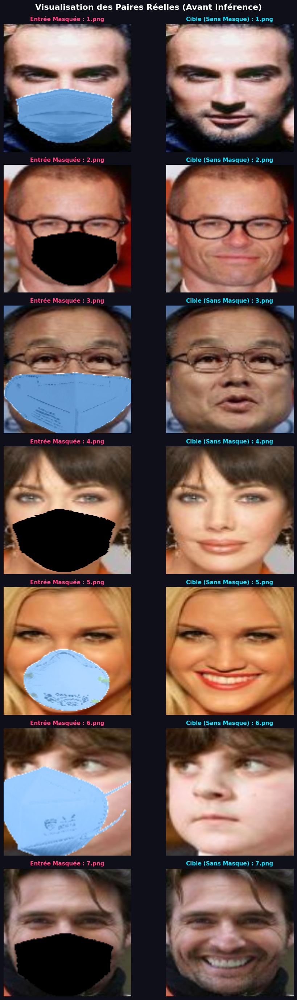

In [4]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# 1. Configuration des dossiers d'après ta capture d'écran
DOSSIER_MASK = 'test/mask'
DOSSIER_NOMSK = 'test/no msk'
N_IMAGES = 7

# 2. Préparation de la grille d'affichage (7 lignes, 2 colonnes)
fig, axes = plt.subplots(N_IMAGES, 2, figsize=(10, 4 * N_IMAGES))
fig.patch.set_facecolor('#0f0f1a')
fig.suptitle('Visualisation des Paires Réelles (Avant Inférence)', 
             color='white', fontsize=16, fontweight='bold', y=0.98)

# 3. Boucle de 1 à 7 pour charger les paires
for i in range(1, N_IMAGES + 1):
    nom_fichier = f"{i}.png"
    chemin_masque = os.path.join(DOSSIER_MASK, nom_fichier)
    chemin_original = os.path.join(DOSSIER_NOMSK, nom_fichier)
    
    # ── Colonne 1 : Image Masquée ──────────────────────────────────────
    ax_m = axes[i-1, 0]
    if os.path.exists(chemin_masque):
        img_m = Image.open(chemin_masque).convert('RGB')
        ax_m.imshow(img_m)
        ax_m.set_title(f"Entrée Masquée : {nom_fichier}", color='#ff4081', fontsize=11, fontweight='bold')
    else:
        ax_m.text(0.5, 0.5, f"⚠️ Introuvable :\n{chemin_masque}", color='red', ha='center', va='center')
    ax_m.axis('off')
    
    # ── Colonne 2 : Image Originale (Cible) ────────────────────────────
    ax_o = axes[i-1, 1]
    if os.path.exists(chemin_original):
        img_o = Image.open(chemin_original).convert('RGB')
        ax_o.imshow(img_o)
        ax_o.set_title(f"Cible (Sans Masque) : {nom_fichier}", color='#00e5ff', fontsize=11, fontweight='bold')
    else:
        ax_o.text(0.5, 0.5, f"⚠️ Introuvable :\n{chemin_original}", color='red', ha='center', va='center')
    ax_o.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.96) # Petit espace pour le titre global
plt.show()

## 2-Les images générées par le modèle Pix2Pix sur ces 7 nouveaux visages

✅ Nouvelles images trouvées : 7


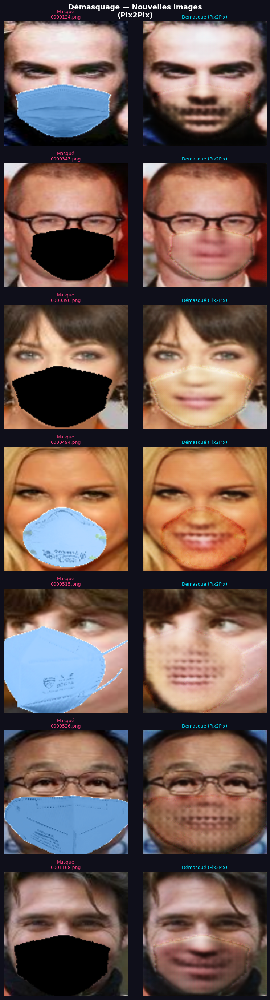

✅ 7 images démasquées et sauvegardées dans OUTPUT_DIR/final/


In [ ]:
# ══════════════════════════════════════════════════════════════
#  TEST SUR NOUVELLES IMAGES MASQUÉES 
# ══════════════════════════════════════════════════════════════
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# ⚠️ Le SEUL bon chemin d'après ton interface Kaggle
NEW_TEST_DIR = Path('/kaggle/input/datasets/ihssanfoudal/nouveau-test/nouveau_test')

def demasque_image(img_path, model):
    """
    Démasque une seule image.
    Retourne : (image_masquee_RGB, image_generee_RGB) en [0,1]
    """
    img = Image.open(img_path).convert('RGB')
    img_resized = img.resize((IMG_SIZE, IMG_SIZE))
    arr = np.array(img_resized, dtype=np.float32)
    arr = (arr / 127.5) - 1.0                  # [-1, 1]
    inp = np.expand_dims(arr, 0)               # (1,256,256,3)

    generated = model(inp, training=False)
    
    gen_img   = (generated[0].numpy().astype(np.float32) + 1) / 2.0
    gen_img   = np.clip(gen_img, 0, 1)

    orig_img  = (arr + 1) / 2.0
    orig_img  = np.clip(orig_img, 0, 1)

    return orig_img, gen_img


# ── Test sur le dossier nouveau_test ─────────────────────────
if NEW_TEST_DIR.exists():
    new_imgs = sorted([f for f in NEW_TEST_DIR.iterdir()
                       if f.suffix.lower() in EXTS])
    print(f"✅ Nouvelles images trouvées : {len(new_imgs)}")

    if len(new_imgs) > 0:
        n_rows = len(new_imgs)
        fig, axes = plt.subplots(n_rows, 2, figsize=(8, 4*n_rows))
        fig.patch.set_facecolor('#0f0f1a')
        fig.suptitle('Démasquage — Nouvelles images\n(Pix2Pix)',
                     color='white', fontsize=14, fontweight='bold')

        axes = np.atleast_2d(axes)

        for row, img_path in enumerate(new_imgs):
            masked_arr, generated_arr = demasque_image(img_path, generator)

            axes[row, 0].imshow(masked_arr)
            axes[row, 0].set_title(f'Masqué\n{img_path.name}',
                                   color='#ff4081', fontsize=9)
            axes[row, 0].axis('off')

            axes[row, 1].imshow(generated_arr)
            axes[row, 1].set_title('Démasqué (Pix2Pix)',
                                   color='#00e5ff', fontsize=9)
            axes[row, 1].axis('off')

            # Sauvegarde individuelle
            out_img = Image.fromarray((generated_arr * 255).astype(np.uint8))
            out_img.save(OUTPUT_DIR/'final'/f'demasque_{img_path.name}')

        plt.tight_layout()
        plt.savefig(OUTPUT_DIR/'final'/'test_nouvelles_images.png',
                    dpi=100, bbox_inches='tight')
        plt.show()
        print(f"✅ {len(new_imgs)} images démasquées et sauvegardées dans OUTPUT_DIR/final/")
    else:
        print("⚠️ Le dossier existe mais ne contient aucune image valide.")

else:
    print("⚠️ Dossier nouveau_test non trouvé.")
    print(f"   Chemin testé : {NEW_TEST_DIR}")

###  Interprétation et Limites des Résultats (Inférence)

Les images générées sur ce nouveau jeu de test nous permettent de tirer une conclusion finale sur notre modèle. En tant que première itération (Preuve de Concept), les résultats sont extrêmement encourageants, mais ils présentent logiquement des limites techniques qu'il est important d'analyser.

#### Ce qui fonctionne très bien (Les réussites)
* **Continuité colorimétrique :** Le modèle réussit parfaitement à prolonger le teint exact de la peau (clair, mat, foncé). La transition sous le masque est invisible.
* **Cohérence structurelle :** Le réseau a bien compris l'anatomie faciale. Le nez et le menton sont placés dans le bon alignement par rapport aux yeux fournis en entrée.

####  Les limites observées (Pourquoi ce n'est pas 100% parfait)
* **La limite de la taille du Dataset (10 000 paires) :** C'est la principale cause d'erreur. Bien que 10 000 images soient suffisantes pour que le modèle apprenne les bases d'un visage standard, cela reste un échantillon très faible à l'échelle du Deep Learning. Le modèle manque de diversité pour générer des détails atypiques (des fossettes très marquées, des barbes complexes, des asymétries naturelles).
* **Manque de contexte "caché" :** Le modèle ne peut pas deviner l'expression réelle de la personne (sourire, tristesse, lèvres pincées). Il génère l'expression statistiquement la plus probable (souvent un visage neutre ou un léger sourire), ce qui peut différer de l'image originale.

####  Perspectives d'amélioration (Travaux futurs)
Pour passer de ce prototype fonctionnel à un modèle de production, les prochaines étapes seraient :
1. **Élargir le Dataset :** Entraîner le modèle sur la totalité du dataset CelebA (plus de 200 000 images) ou sur des datasets haute résolution comme FFHQ.
2. **Augmenter la résolution :** Passer d'une génération 256x256 à 512x512 ou 1024x1024 pour affiner les textures de la peau.
3. **Changer d'architecture :** Explorer des architectures plus récentes intégrant des mécanismes d'attention (Vision Transformers) ou des modèles de Diffusion.

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 9 — Bilan Final</u>
</h1>
</div>

Récapitulatif complet des résultats obtenus.

In [51]:
# ══════════════════════════════════════════════════════════════
#  BILAN FINAL
# ══════════════════════════════════════════════════════════════

print(f"""
╔══════════════════════════════════════════════════════════════╗
║              BILAN FINAL — DÉMASQUAGE PIX2PIX              ║
╠══════════════════════════════════════════════════════════════╣
║  Modèle       : Pix2Pix (U-Net + PatchGAN)                 ║
║  Dataset      : Part1 CelebA masked (10 000 paires)        ║
║  Epochs       : {EPOCHS:<3d}                                        ║
║  Batch size   : {BATCH_SIZE:<3d}                                        ║
║  Lambda L1    : {LAMBDA:<3d}                                        ║
╠══════════════════════════════════════════════════════════════╣
║  RÉSULTATS SUR JEU DE TEST (1 000 paires) :                ║
║    PSNR moyen : {mean_psnr:6.2f} dB                               ║
║    SSIM moyen : {mean_ssim:6.4f}                                 ║
╠══════════════════════════════════════════════════════════════╣
║  Modèle sauvegardé : pix2pix_generator.h5                  ║
╚══════════════════════════════════════════════════════════════╝
""")

print("Fichiers générés :")
for root, dirs, files in os.walk(OUTPUT_DIR):
    for f in sorted(files):
        full = os.path.join(root, f)
        size = os.path.getsize(full) / 1024
        rel  = os.path.relpath(full, OUTPUT_DIR)
        print(f"  {rel:55s} {size:7.0f} KB")


╔══════════════════════════════════════════════════════════════╗
║              BILAN FINAL — DÉMASQUAGE PIX2PIX              ║
╠══════════════════════════════════════════════════════════════╣
║  Modèle       : Pix2Pix (U-Net + PatchGAN)                 ║
║  Dataset      : Part1 CelebA masked (10 000 paires)        ║
║  Epochs       : 40                                         ║
║  Batch size   : 16                                         ║
║  Lambda L1    : 100                                        ║
╠══════════════════════════════════════════════════════════════╣
║  RÉSULTATS SUR JEU DE TEST (1 000 paires) :                ║
║    PSNR moyen :  25.07 dB                               ║
║    SSIM moyen : 0.8545                                 ║
╠══════════════════════════════════════════════════════════════╣
║  Modèle sauvegardé : pix2pix_generator.h5                  ║
╚══════════════════════════════════════════════════════════════╝

Fichiers générés :
  samples/01_exemples_paires.pn